-----

# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.

[Te proporcionamos algunos comentarios para orientarte mientras completas este proyecto. Pero debes asegurarte de eliminar todos los comentarios entre corchetes antes de entregar tu proyecto.]

[Antes de sumergirte en el análisis de datos, explica por tu propia cuenta el propósito del proyecto y las acciones que planeas realizar.]

[Ten en cuenta que estudiar, modificar y analizar datos es un proceso iterativo. Es normal volver a los pasos anteriores y corregirlos/ampliarlos para permitir nuevos pasos.]

## Inicialización

In [1]:
# Cargar todas las librerías
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import math
import scipy.stats as st




pd.set_option('display.float_format', '{:.2f}'.format)


## Cargar datos

In [ ]:
# Carga los archivos de datos en diferentes DataFrames
from pathlib import Path
base_candidates = [Path('Analisis_estadistico') / 'dfs', Path('dfs')]
for base in base_candidates:
    if (base / 'megaline_calls.csv').exists():
        calls = pd.read_csv(base / 'megaline_calls.csv')
        internet = pd.read_csv(base / 'megaline_internet.csv')
        messages = pd.read_csv(base / 'megaline_messages.csv')
        plans = pd.read_csv(base / 'megaline_plans.csv')
        users = pd.read_csv(base / 'megaline_users.csv')
        break
else:
    raise FileNotFoundError('No se encontraron los CSV en Analisis_estadistico/dfs o dfs/')



## Preparar los datos

[Los datos para este proyecto se dividen en varias tablas. Explora cada una para tener una comprensión inicial de los datos. Si es necesario, haz las correcciones requeridas en cada tabla.]

## Tarifas

In [3]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas
print(plans.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes
None


In [4]:
# Imprime una muestra de los datos para las tarifas

print(plans)

   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  


[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?] 


En este dataset lo unico que corregiria de momento seria el hecho de que los precios por minuto y por mensaje estan en float pero no deberia ya que todo se cobra por entero.

## Corregir datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

## Enriquecer los datos

[Agrega factores adicionales a los datos si crees que pudieran ser útiles.]

## Usuarios/as

In [5]:
# Imprime la información general/resumida sobre el DataFrame de usuarios
print(users.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB
None


In [6]:
# Imprime una muestra de datos para usuarios
print(users.sample())

     user_id first_name last_name  age  \
314     1314      Brice    Morgan   35   

                                       city    reg_date      plan churn_date  
314  Los Angeles-Long Beach-Anaheim, CA MSA  2018-03-06  ultimate        NaN  


[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?]

no, de acuerdo a la informacion mostrada todo parece estar correcto, como mencione antes el churn date no veo incorrecto que este en NaN

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [7]:
users['churn_date'] = pd.to_datetime(users['churn_date'], errors='coerce')


## Llamadas

In [8]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas

print(calls.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB
None


In [9]:
# Imprime una muestra de datos para las llamadas

print(calls.sample())
calls.info()

           id  user_id   call_date  duration
152  1001_260     1001  2018-11-28      7.06
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?]

Unicamente corregiria el tipo de dato de call_date, en este caso como son pocos datos lo podemos hacer sin mayor preocupacion pero de acuerdo al tamaño del dataset habria que evaluar si realmente se va a hacer algo con estos datos o no conviene hacer la conversion 

Tambien la duracion ya que solo se cobran enteros entonces por eso redondamos al siguiente numero hacia arriba.

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [10]:
calls['duration']= calls['duration'].apply(math.ceil)
calls['call_date']= pd.to_datetime(calls['call_date'], errors='coerce')


## Mensajes

In [11]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes

messages.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


In [12]:
# Imprime una muestra de datos para los mensajes
messages.sample()


,id,user_id,message_date
355,1003_49,1003,2018-12-24


[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?]


Unicamente corregiria el tipo de dato de message_date, en este caso como son pocos datos lo podemos hacer sin mayor preocupacion pero de acuerdo al tamaño del dataset habria que evaluar si realmente se va a hacer algo con estos datos o no conviene hacer la conversion 

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [13]:
messages['message_date']= pd.to_datetime(messages['message_date'], errors='coerce')

## Internet

In [14]:
# Imprime la información general/resumida sobre el DataFrame de internet

internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


In [15]:
# Imprime una muestra de datos para el tráfico de internet

internet.sample()

,id,user_id,session_date,mb_used
71242,1332_215,1332,2018-12-05,2.27


[Describe lo que ves y observas en la información general y en la muestra de datos impresa para el precio de datos anterior. ¿Hay algún problema (tipos de datos no adecuados, datos ausentes, etc.) que pudieran necesitar investigación y cambios adicionales? ¿Cómo se puede arreglar?]



Unicamente corregiria el tipo de dato de session_date, en este caso como son pocos datos lo podemos hacer sin mayor preocupacion pero de acuerdo al tamaño del dataset habria que evaluar si realmente se va a hacer algo con estos datos o no conviene hacer la conversion 

Tambien mb_used ya que solo se cobran enteros entonces por eso redondamos al siguiente numero hacia arriba.

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [16]:
internet['session_date']=pd.to_datetime(internet['session_date'], errors='coerce')
internet['mb_used']= internet['mb_used'].apply(math.ceil)

## Estudiar las condiciones de las tarifas

[Es sumamente importante entender cómo funcionan las tarifas, cómo se les cobra a los usuarios en función de su plan de suscripción. Así que te sugerimos imprimir la información de la tarifa para ver una vez más sus condiciones.]

In [17]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras
print(plans)


   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  


## Agregar datos por usuario

[Ahora que los datos están limpios, agrega los datos por usuario y por periodo para que solo haya un registro por usuario y por periodo. Esto facilitará mucho el análisis posterior.]

In [18]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.

calls['month']= calls['call_date'].dt.to_period('M')
call_per_month = calls.groupby(['user_id','month']).size().reset_index(name='calls_made')

In [19]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.

duration_per_month= calls.groupby(['user_id','month'])['duration'].sum().reset_index(name='total_minutes_per_month')


In [20]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.
messages['month']=messages['message_date'].dt.to_period('M')
messages_per_month = messages.groupby(['user_id','month']).size().reset_index(name='messages_sent_per_month')

In [21]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.
internet['month']= internet['session_date'].dt.to_period('M')
mb_spend_per_month = internet.groupby(['user_id','month'])['mb_used'].sum().reset_index(name='total_mb_used_by_month')


[Junta los datos agregados en un DataFrame para que haya un registro que represente lo que consumió un usuario único en un mes determinado.]

In [22]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month
user_summary = call_per_month.merge(duration_per_month, on=['user_id','month'])
user_summary= user_summary.merge(messages_per_month, on=['user_id','month'])
user_summary = user_summary.merge(mb_spend_per_month, on=['user_id','month'])


print(user_summary.head())

   user_id    month  calls_made  total_minutes_per_month  \
0     1000  2018-12          16                      124   
1     1001  2018-08          27                      182   
2     1001  2018-09          49                      315   
3     1001  2018-10          65                      393   
4     1001  2018-11          64                      426   

   messages_sent_per_month  total_mb_used_by_month  
0                       11                    1903  
1                       30                    6929  
2                       44                   13333  
3                       53                   22356  
4                       36                   18524  


In [23]:
# Añade la información de la tarifa
user_summary= user_summary.merge(users[['plan','user_id']],on='user_id')
user_summary= user_summary.merge(plans, left_on='plan', right_on='plan_name')
user_summary.sample(3)


,user_id,month,calls_made,total_minutes_per_month,messages_sent_per_month,total_mb_used_by_month,plan,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
223,1188,2018-12,26,182,52,20403,ultimate,1000,30720,3000,70,7,0.01,0.01,ultimate
801,1100,2018-09,67,497,45,18972,surf,50,15360,500,20,10,0.03,0.03,surf
1550,1385,2018-04,78,620,36,11979,surf,50,15360,500,20,10,0.03,0.03,surf


[Calcula los ingresos mensuales por usuario (resta el límite del paquete gratuito del número total de llamadas, mensajes de texto y datos; multiplica el resultado por el valor del plan de llamadas; añade la tarifa mensual en función del plan de llamadas). Nota: Dadas las condiciones del plan, ¡esto podría no ser tan trivial como un par de líneas! Así que no pasa nada si dedicas algo de tiempo a ello.]

In [24]:
# Calcula el ingreso mensual para cada usuario
user_summary['extra_calls']=np.maximum(user_summary['total_minutes_per_month']-user_summary['minutes_included'],0)
user_summary['extra_messages']=np.maximum(user_summary['messages_sent_per_month']-user_summary['messages_included'],0)
user_summary['extra_gb']= np.maximum(user_summary['total_mb_used_by_month']-user_summary['mb_per_month_included'],0)
user_summary['extra_gb']=  np.ceil(user_summary['extra_gb']/1024)

user_summary['extra_calls']= user_summary['extra_calls'] * user_summary['usd_per_minute']
user_summary['extra_messages']= user_summary['extra_messages'] * user_summary['usd_per_message']
user_summary['extra_gb']=  user_summary['extra_gb']* user_summary['usd_per_gb']


user_summary['total_income_by_user']= user_summary['extra_calls'] + user_summary['extra_messages'] + user_summary['extra_gb'] 
user_summary['total_income_by_user'] +=  user_summary['usd_monthly_pay']

print(user_summary.sample(3))


user_summary.groupby(by='user_id')['total_income_by_user'].sum()



      user_id    month  calls_made  total_minutes_per_month  \
989      1175  2018-10         101                      703   
660      1054  2018-07          44                      315   
1285     1291  2018-07          79                      642   

      messages_sent_per_month  total_mb_used_by_month  plan  \
989                        31                   22587  surf   
660                        25                   16309  surf   
1285                       10                   21523  surf   

      messages_included  mb_per_month_included  minutes_included  \
989                  50                  15360               500   
660                  50                  15360               500   
1285                 50                  15360               500   

      usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  \
989                20          10             0.03            0.03      surf   
660                20          10             0.03           

user_id
1000    70.00
1001   250.09
1002   100.00
1003   158.12
1004   610.00
        ...  
1491   163.12
1492   100.00
1494   193.75
1496   140.00
1497    70.00
Name: total_income_by_user, Length: 393, dtype: float64

## Estudia el comportamiento de usuario

[Calcula algunas estadísticas descriptivas para los datos agregados y fusionados que nos sean útiles y que muestren un panorama general captado por los datos. Dibuja gráficos útiles para facilitar la comprensión. Dado que la tarea principal es comparar las tarifas y decidir cuál es más rentable, las estadísticas y gráficas deben calcularse por tarifa.]

[En los comentarios hallarás pistas relevantes para las llamadas, pero no las hay para los mensajes e Internet. Sin embargo, el principio del estudio estadístico que se aplica para ellos es el mismo que para las llamadas.]

### Llamadas

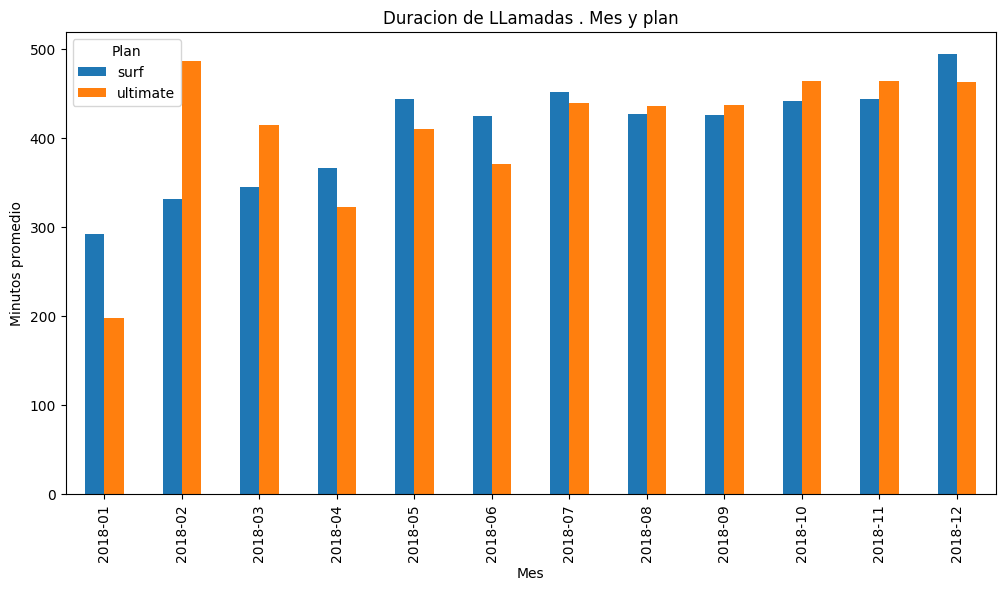

       user_id  calls_made  total_minutes_per_month  messages_sent_per_month  \
count  1759.00     1759.00                  1759.00                  1759.00   
mean   1244.97       62.23                   444.70                    41.78   
std     139.29       32.84                   239.96                    32.67   
min    1000.00        1.00                     0.00                     1.00   
25%    1126.00       40.00                   279.00                    17.00   
50%    1246.00       61.00                   433.00                    34.00   
75%    1362.00       81.00                   586.00                    59.00   
max    1497.00      205.00                  1510.00                   266.00   

       total_mb_used_by_month  messages_included  mb_per_month_included  \
count                 1759.00            1759.00                1759.00   
mean                 16853.43             362.71               20415.96   
std                   7716.04             446.54      

In [25]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.
grouped= user_summary.groupby(['plan_name','month'])
grouped1= user_summary.groupby(['plan_name','month'])['total_minutes_per_month'].mean().reset_index()
pivoted = grouped1.pivot(index='month', columns='plan_name', values='total_minutes_per_month')

pivoted.plot(kind='bar',figsize=(12,6))

plt.title('Duracion de LLamadas . Mes y plan')
plt.xlabel('Mes')
plt.ylabel('Minutos promedio')
plt.legend(title='Plan')
plt.show()

print(user_summary.describe())


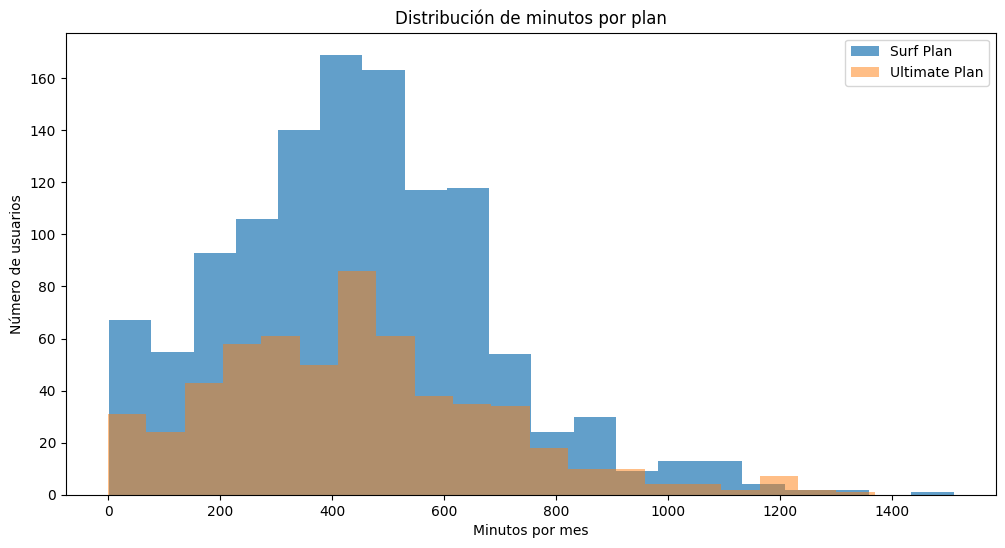

In [26]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.

plt.figure(figsize=(12,6))

surf = user_summary[user_summary['plan_name'] == 'surf']['total_minutes_per_month']
plt.hist(surf, bins=20, alpha=0.7, label='Surf Plan')

ultimate = user_summary[user_summary['plan_name'] == 'ultimate']['total_minutes_per_month']
plt.hist(ultimate, bins=20, alpha=0.5, label='Ultimate Plan')

plt.xlabel('Minutos por mes')
plt.ylabel('Número de usuarios')
plt.title('Distribución de minutos por plan')
plt.legend()
plt.show()


[Calcula la media y la variable de la duración de las llamadas para averiguar si los usuarios de los distintos planes se comportan de forma diferente al realizar sus llamadas.]

In [27]:
# Calcula la media y la varianza de la duración mensual de llamadas.
calls_mean = user_summary['total_minutes_per_month'].mean()
calls_var= user_summary['total_minutes_per_month'].var()

<Figure size 1200x600 with 0 Axes>

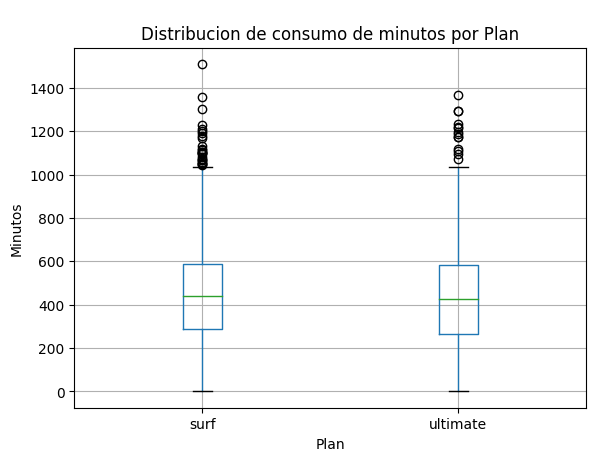

plan_name
surf        13
ultimate     5
Name: user_id, dtype: int64


In [28]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas
plt.figure(figsize=(12,6))
user_summary.boxplot(column='total_minutes_per_month', by='plan_name')
plt.title('Distribucion de consumo de minutos por Plan')
plt.suptitle(' ')
plt.xlabel('Plan')
plt.ylabel('Minutos')

plt.show()

q1 = user_summary['total_minutes_per_month'].quantile(0.25)
q3 = user_summary['total_minutes_per_month'].quantile(0.75)
iqr = q3 - q1

# Filtramos los outliers
outliers = user_summary[user_summary['total_minutes_per_month'] > (q3 + 1.5 * iqr)]

# Agrupamos por plan y contamos usuarios únicos
outliers_count = outliers.groupby('plan_name')['user_id'].nunique()

print(outliers_count)


[Elabora las conclusiones sobre el comportamiento de los usuarios con respecto a las llamadas. ¿Su comportamiento varía en función del plan?]

De acuerdo a los graficos podemos determinar que realmente no cmabia mucho los minutos utilizados al mes de acuerdo al plan, sin embargo lo que si podemos notar es un cambio en el promedio de minutos en el mes de febrero (graifco 1), valdia la pena analizar mas a detalle cual fue el uso para determinar a que se debio ese aumento.

En el segundo grafico, podemos ver que ambos planes estan cercanos a los valores promedio sin embargo la distribucion de usuarios es bastante diferente, siendo bastante superior la cantidad de usuarios del plan surf que la del plan ultimate. 

En el tercer grafico vemos que la distribucion de datos presenta datos anormales habria que indagar sobre el uso de esos usuarios para ver si es mas conveniente ofrecerles un mejor plan en el caso de surf o mejorar la oferta de ambos paquetes. 

### Mensajes

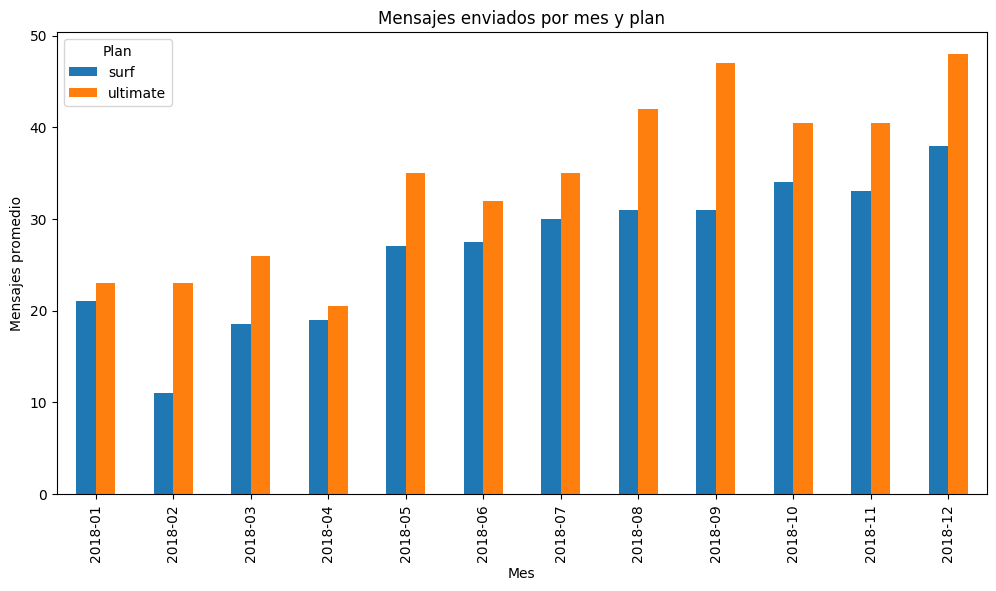

In [29]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan

grouped= user_summary.groupby(['month','plan_name'])['messages_sent_per_month'].median().reset_index()
pivoted= grouped.pivot(index='month', columns='plan_name', values='messages_sent_per_month')

pivoted.plot(kind='bar', figsize=(12,6))
plt.title('Mensajes enviados por mes y plan')
plt.xlabel('Mes')
plt.ylabel('Mensajes promedio')
plt.legend(title='Plan')
plt.show()

In [30]:
calls_mean = user_summary['messages_sent_per_month'].mean()
calls_var= user_summary['messages_sent_per_month'].var()



<Figure size 1200x600 with 0 Axes>

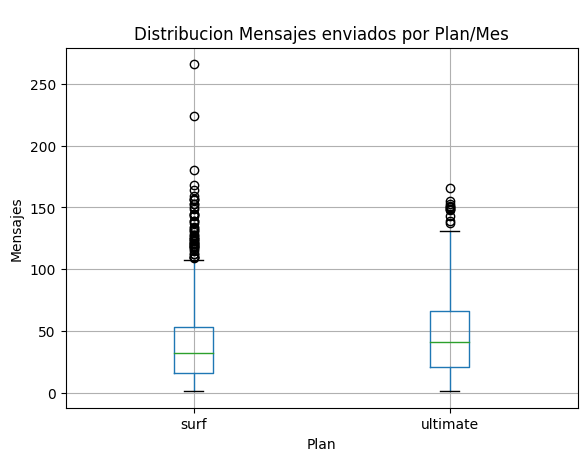

plan_name
surf        13
ultimate     9
Name: user_id, dtype: int64


In [31]:
plt.figure(figsize=(12,6))
user_summary.boxplot(column='messages_sent_per_month', by='plan_name')
plt.title('Distribucion Mensajes enviados por Plan/Mes')
plt.suptitle(' ')
plt.xlabel('Plan')
plt.ylabel('Mensajes')

plt.show()

q1 = user_summary['messages_sent_per_month'].quantile(0.25)
q3 = user_summary['messages_sent_per_month'].quantile(0.75)
iqr = q3 - q1

# Filtramos los outliers
outliers = user_summary[user_summary['messages_sent_per_month'] > (q3 + 1.5 * iqr)]

# Agrupamos por plan y contamos usuarios únicos
outliers_count = outliers.groupby('plan_name')['user_id'].nunique()

print(outliers_count)



[Elabora las conclusiones sobre el comportamiento de los usuarios con respecto a los mensajes. ¿Su comportamiento varía en función del plan?]

como observamos en el grafico 1, en general el uso de los mensajes es relativo al mes mas que los planes, ya que en los meses que aumenta el uso en el plan surf tambien lo hace en el plan ultimate, se decide a usar la mediana ya que deacuerdo al box plo tenemos valores anormales, outliers

### Internet

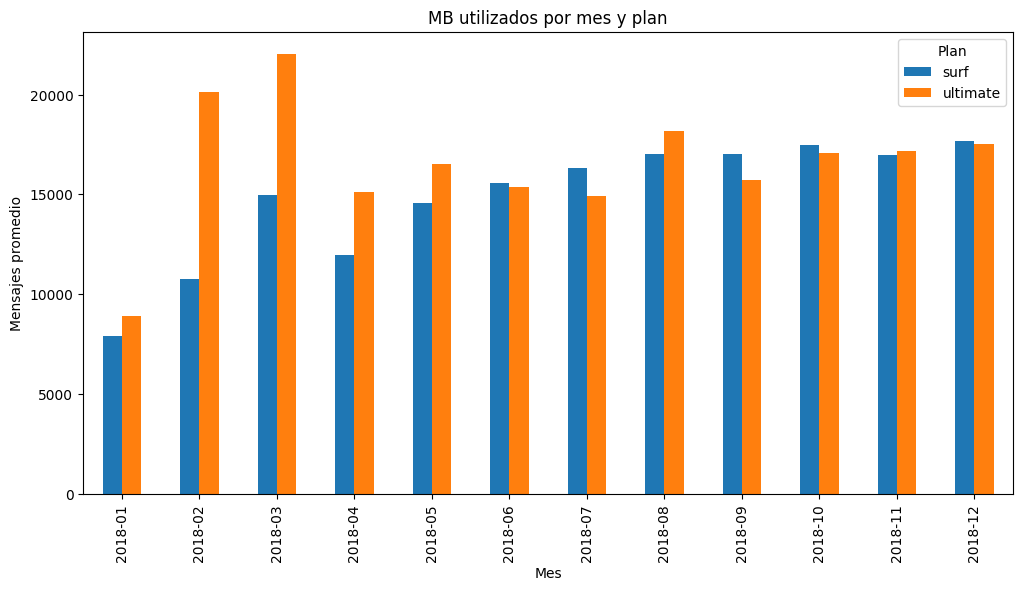

In [32]:
grouped= user_summary.groupby(['month','plan_name'])['total_mb_used_by_month'].median().reset_index()
pivoted= grouped.pivot(index='month', columns='plan_name', values='total_mb_used_by_month')

pivoted.plot(kind='bar', figsize=(12,6))
plt.title('MB utilizados por mes y plan')
plt.xlabel('Mes')
plt.ylabel('Mensajes promedio')
plt.legend(title='Plan')


plt.show()

In [33]:
internet_mean = user_summary['total_mb_used_by_month'].mean()
internet_var= user_summary['total_mb_used_by_month'].var()

<Figure size 1200x600 with 0 Axes>

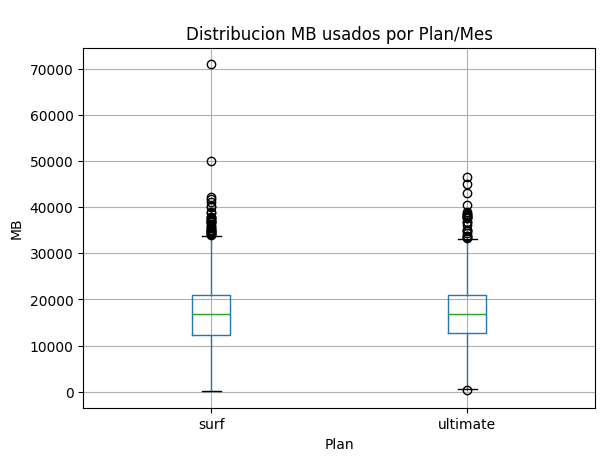

plan_name
surf        18
ultimate    10
Name: user_id, dtype: int64


In [34]:
plt.figure(figsize=(12,6))
user_summary.boxplot(column='total_mb_used_by_month', by='plan_name')
plt.title('Distribucion MB usados por Plan/Mes')
plt.suptitle(' ')
plt.xlabel('Plan')
plt.ylabel('MB')

plt.show()

q1 = user_summary['total_mb_used_by_month'].quantile(0.25)
q3 = user_summary['total_mb_used_by_month'].quantile(0.75)
iqr = q3 - q1

# Filtramos los outliers
outliers = user_summary[user_summary['total_mb_used_by_month'] > (q3 + 1.5 * iqr)]

# Agrupamos por plan y contamos usuarios únicos
outliers_count = outliers.groupby('plan_name')['user_id'].nunique()

print(outliers_count)



[Elabora las conclusiones sobre cómo los usuarios tienden a consumir el tráfico de Internet. ¿Su comportamiento varía en función del plan?]

Si, pero solo en algunos meses es la diferencia. lo que si obersvamos es que tenemos 56 usarios fuera del rango normal de uso, podriamos analizar de acuerdo a su plan actual y su uso si convendria ofrecerles cambiarse al plan ultimate o en caso que no tal vez algun add-on o un nuevo plan para usuarios con necesidades mas grandes de uso de datos.

## Ingreso

[Del mismo modo que has estudiado el comportamiento de los usuarios, describe estadísticamente los ingresos de los planes.]

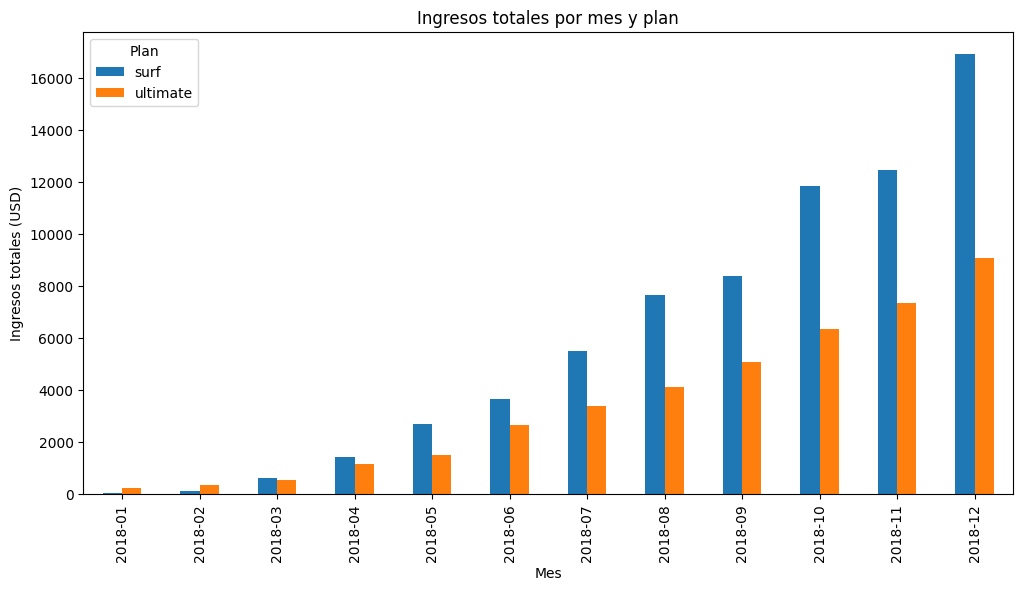

In [35]:
monthly_income = user_summary.groupby(['month', 'plan_name'])['total_income_by_user'].sum().reset_index()

pivot = monthly_income.pivot(index='month', columns='plan_name', values='total_income_by_user')

pivot.plot(kind='bar', figsize=(12,6))

plt.title('Ingresos totales por mes y plan')
plt.xlabel('Mes')
plt.ylabel('Ingresos totales (USD)')
plt.legend(title='Plan')
plt.show()


In [36]:
surf_mean = user_summary[user_summary['plan_name'] == 'surf']['total_income_by_user'].mean()
ultimate_mean = user_summary[user_summary['plan_name'] == 'ultimate']['total_income_by_user'].mean()

surf_var = user_summary[user_summary['plan_name'] == 'surf']['total_income_by_user'].var()
ultimate_var = user_summary[user_summary['plan_name'] == 'ultimate']['total_income_by_user'].var()





<Figure size 1200x600 with 0 Axes>

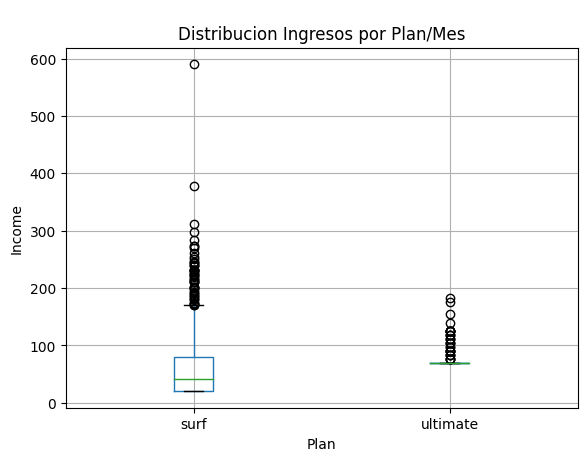

plan_name
surf        49
ultimate     2
Name: user_id, dtype: int64


In [37]:
plt.figure(figsize=(12,6))
user_summary.boxplot(column='total_income_by_user', by='plan_name')

plt.title('Distribucion Ingresos por Plan/Mes')
plt.suptitle(' ')
plt.xlabel('Plan')
plt.ylabel('Income')

plt.show()


q1 = user_summary['total_income_by_user'].quantile(0.25)
q3 = user_summary['total_income_by_user'].quantile(0.75)
iqr = q3 - q1

# Filtramos los outliers
outliers = user_summary[user_summary['total_income_by_user'] > (q3 + 1.5 * iqr)]

# Agrupamos por plan y contamos usuarios únicos
outliers_count = outliers.groupby('plan_name')['user_id'].nunique()

print(outliers_count)



[Elabora las conclusiones sobre cómo difiere el ingreso entre los planes.]


De acuerdo alos ingresos que vemos si bien el plan surf es el que mayor ingreso genera esto se debe principalmente a la cantidad de usuarios que tenemos para este plan, pero tambiena que tenemos un uso excesivo de algunos sertvicios sobre todo en llamadas en el plan surf en las llamdas y tambien en uso de datos 

## Prueba las hipótesis estadísticas

[Prueba la hipótesis de que son diferentes los ingresos promedio procedentes de los usuarios de los planes de llamada Ultimate y Surf.]

[Elabora las hipótesis nula y alternativa, escoge la prueba estadística, determina el valor alfa.]

In [38]:
# Prueba las hipótesis, ambos palnes generan el mismo ingreso 
surf_income=user_summary[user_summary['plan_name']=='surf']['total_income_by_user']
ultimate_income=user_summary[user_summary['plan_name']=='ultimate']['total_income_by_user']

p_value = st.ttest_ind(surf_income, ultimate_income, equal_var=False).pvalue

if p_value < 0.05:
    print("Rechazamos la hipótesis nula: hay diferencia significativa en los ingresos.")
else:
    print("No hay evidencia suficiente para decir que los ingresos son diferentes.")

Rechazamos la hipótesis nula: hay diferencia significativa en los ingresos.


[Prueba la hipótesis de que el ingreso promedio de los usuarios del área NY-NJ es diferente al de los usuarios de otras regiones.]

[Elabora las hipótesis nula y alternativa, escoge la prueba estadística, determina el valor alfa.]

In [39]:
# Prueba las hipótesis

user_summary = user_summary.merge(users[['user_id', 'city']], on='user_id', how='left')

ny_income = user_summary[user_summary['city'].str.endswith('NY-NJ-PA')]['total_income_by_user']
other_income = user_summary[~user_summary['city'].str.endswith('NY-NJ-PA')]['total_income_by_user']

p_value = st.ttest_ind(ny_income, other_income, equal_var=False).pvalue

if p_value < 0.05:
    print("Rechazamos la hipótesis nula: hay diferencia significativa en los ingresos entre NY-NJ y otras regiones.")
else:
    print("No hay evidencia suficiente para decir que los ingresos son diferentes.")


No hay evidencia suficiente para decir que los ingresos son diferentes.


## Conclusión general

[En esta sección final, enumera tus conclusiones importantes. Asegúrate de que estas abarquen todas las decisiones (suposiciones) importantes que adoptaste y que determinaron la forma elegida para procesar y analizar los datos.]

[1 en podemos determinar que para algunos usuarios se dispara el uso de llamdas, por lo tanto puede que sea innecesario sin tener que llegar a optar pr el cambio al plan ultimate ya que no justifica el precio el uso de los demas servicios

En general el uso promedio de los mensajes es muy bajo por lo tanto podria analizarse la opcion de reducir la cantidad de mensajes por plan y tal vez mover esos recursos a servicios que si se utilicen y sean equiparables, por ejemplo las llamadas que tienen el mismo costo en excedentes. 

En cuanto al uso de datos nuevamente se dispara, lo que puede ser insuficiente o da oportunidad de pensar en un nuevo paquete o algun addon para usuarios con necesidades mas altas de datos, tambien valdria la pena analizar el uso de los datos(streaming, aplicaciones de mensajeria, navegacion web, etc.)

En General el ingreso de los usuarios surf representa un mucho mayor ingreso, ademas de que al haber mas hay mas excedentes lo cual da oportunidad a analizar la posibilidad de modificar los planes existentes, para saber si es posible como mencione anteriormente 'cambiar' unos servicios por otros, o bien crear addons que permita generar un ingreso mayor al mismo tiempo que ofrecer un mejor servicio a los clientes
]